** Part 1: Data Exploration and Preparation**

In [59]:
#import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import string

from collections import Counter

In [60]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [61]:
# Load the data
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/project7/twitter_disaster.csv")

In [62]:
df.head(10)

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
5,8,NaN,NaN,#RockyFire Update => California Hwy. 20 closed...,1
6,10,NaN,NaN,#flood #disaster Heavy rain causes flash flood...,1
7,13,NaN,NaN,I'm on top of the hill and I can see a fire in...,1
8,14,NaN,NaN,There's an emergency evacuation happening now ...,1
9,15,NaN,NaN,I'm afraid that the tornado is coming to our a...,1


In [63]:
df.shape

(7613, 5)

In [64]:
df.columns

Index(['id', 'keyword', 'location', 'text', 'target'], dtype='object')

In [65]:
# Display summary statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,7613.0,NaN,NaN,NaN,5441.934848,3137.11609,1.0,2734.0,5408.0,8146.0,10873.0
keyword,7552,221,fatalities,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,5079,3293,USA,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,7613,7503,11-Year-Old Boy Charged With Manslaughter of T...,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,7613.0,NaN,NaN,NaN,0.42966,0.49506,0.0,0.0,0.0,1.0,1.0


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5079 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


In [67]:
df.drop("id",axis=1,inplace=True)

In [68]:
df.columns

Index(['keyword', 'location', 'text', 'target'], dtype='object')

In [69]:
# Null Value
df.isnull().sum()

,0
keyword,61
location,2534
text,0
target,0


In [70]:
# Fill the missing values

df["keyword"] = df["keyword"].fillna("Unknown")
df["location"] = df["location"].fillna("Unknown")



In [71]:
df.isnull().sum()

,0
keyword,0
location,0
text,0
target,0


In [72]:
# Duplicate values
df.duplicated().sum()

np.int64(52)

In [73]:
df.drop_duplicates(inplace=True)

In [74]:
df.shape

(7561, 4)

In [75]:
# Visualize the class distribution - 0 = non-disaster tweet /1 = disaster tweet

print(df["target"].value_counts())
print("\nTarget percentages:")
print(df["target"].value_counts(normalize=True) * 100)

target
0    4322
1    3239
Name: count, dtype: int64

Target percentages:
target
0    57.161751
1    42.838249
Name: proportion, dtype: float64


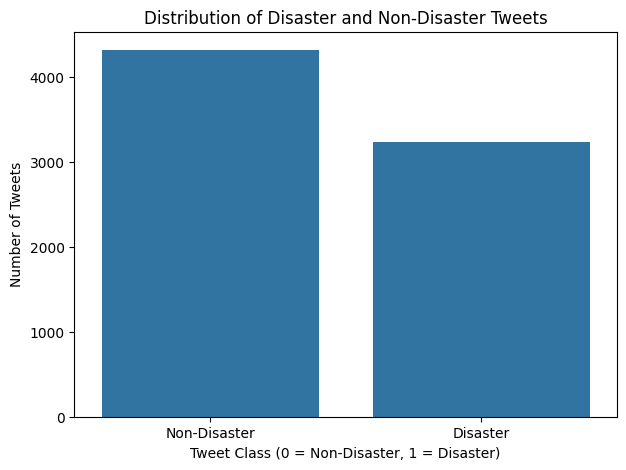

In [76]:
# bar plot

class_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Distribution of Disaster and Non-Disaster Tweets")
plt.xlabel("Tweet Class (0 = Non-Disaster, 1 = Disaster)")
plt.ylabel("Number of Tweets")
plt.xticks([0, 1], ["Non-Disaster", "Disaster"])

plt.show()

**Class Observation **

The dataset contains 7,613 tweets, including 4,342 non-disaster tweets (57.03%) and 3,271 disaster tweets (42.97%). Non-disaster tweets represent the majority class. Although the classes are not perfectly balanced, the difference is moderate. Therefore, stratified train-test splitting will help preserve the class proportions in the training and testing datasets. Model performance should be evaluated using precision, recall, F1-score, and accuracy rather than accuracy alone.

In [77]:
# Analyze keywords associated with disaster tweets

# Select only disaster tweets
disaster_tweets = df[df["target"] == 1]

# Count the most frequent keywords
top_keywords = (
    disaster_tweets["keyword"]
    .dropna()
    .str.replace("%20", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .value_counts()
    .head(15)
)

print(top_keywords)

keyword
Unknown             42
wreckage            39
outbreak            38
debris              37
typhoon             37
oil spill           37
derailment          35
evacuated           32
razed               31
nuclear disaster    31
suicide bombing     31
earthquake          30
suicide bomber      30
bridge collapse     29
collision           29
Name: count, dtype: int64


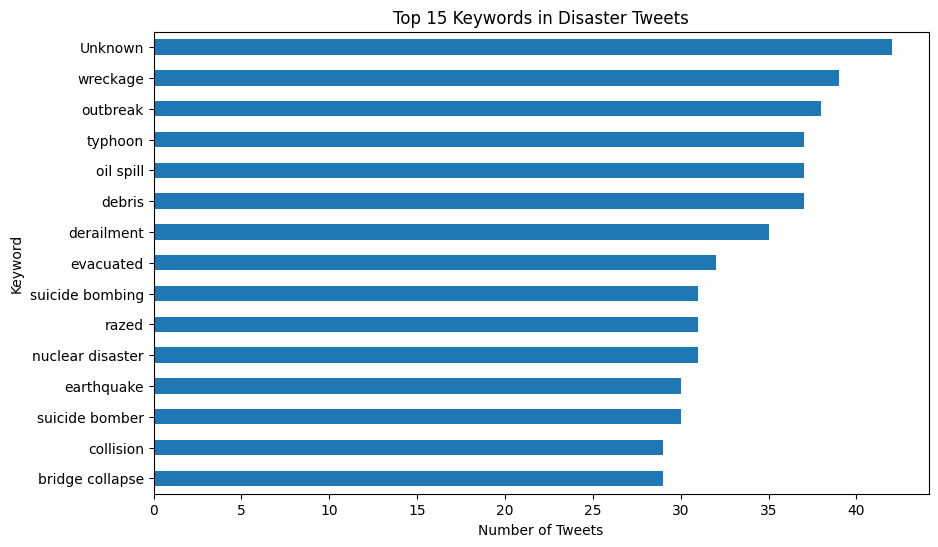

In [78]:
# Plot the top 15 keywords

plt.figure(figsize=(10, 6))

top_keywords.sort_values().plot(kind="barh")

plt.title("Top 15 Keywords in Disaster Tweets")
plt.xlabel("Number of Tweets")
plt.ylabel("Keyword")

plt.show()

In [79]:
# Create a text-cleaning function
def clean_text(text):
    # Handle missing values
    if pd.isna(text):
        return ""

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove user mentions
    text = re.sub(r"@\w+", "", text)

    # Remove hashtag symbol but keep the word
    text = re.sub(r"#", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [80]:
# Apply the cleaning function
df["clean_text"] = df["text"].apply(clean_text)

# Compare original and cleaned tweets
df[["text", "clean_text"]].head(10)

,text,clean_text
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...
3,"13,000 people receive #wildfires evacuation or...",13 000 people receive wildfires evacuation ord...
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...
5,#RockyFire Update => California Hwy. 20 closed...,rockyfire update california hwy 20 closed in b...
6,#flood #disaster Heavy rain causes flash flood...,flood disaster heavy rain causes flash floodin...
7,I'm on top of the hill and I can see a fire in...,i m on top of the hill and i can see a fire in...
8,There's an emergency evacuation happening now ...,there s an emergency evacuation happening now ...
9,I'm afraid that the tornado is coming to our a...,i m afraid that the tornado is coming to our area


In [81]:
#Check whether cleaning worked

print("Original tweet:")
print(df["text"].iloc[0])

print("\nCleaned tweet:")
print(df["clean_text"].iloc[0])

print("\nMissing cleaned tweets:", df["clean_text"].isnull().sum())
print("Empty cleaned tweets:", (df["clean_text"] == "").sum())

Original tweet:
Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all

Cleaned tweet:
our deeds are the reason of this earthquake may allah forgive us all

Missing cleaned tweets: 0
Empty cleaned tweets: 0


In [82]:
# Tokenize the tweets

# Split each cleaned tweet into individual words
df["tokens"] = df["clean_text"].apply(lambda text: text.split())

# Display original text, cleaned text, and tokens
df[["text", "clean_text", "tokens"]].head(5)

,text,clean_text,tokens
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...,"[our, deeds, are, the, reason, of, this, earth..."
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]"
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...,"[all, residents, asked, to, shelter, in, place..."
3,"13,000 people receive #wildfires evacuation or...",13 000 people receive wildfires evacuation ord...,"[13, 000, people, receive, wildfires, evacuati..."
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...,"[just, got, sent, this, photo, from, ruby, ala..."


In [83]:
# Verify the target labels

print("Target data type:", df["target"].dtype)
print("Unique target values:", df["target"].unique())
print(df["target"].value_counts())


Target data type: int64
Unique target values: [1 0]
target
0    4322
1    3239
Name: count, dtype: int64


In [84]:
df["target"] = df["target"].astype(int)

In [85]:
#Check for empty cleaned tweets

empty_tweets = df[df["clean_text"].str.strip() == ""]

print("Number of empty cleaned tweets:", len(empty_tweets))

Number of empty cleaned tweets: 0


In [86]:
# Split the dataset into training and testing sets

# Keep rows with non-empty cleaned text
df_model = df[df["clean_text"].str.strip() != ""].copy()

# Define features and target
X = df_model["clean_text"]
y = df_model["target"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)



X_train shape: (6048,)
X_test shape: (1513,)
y_train shape: (6048,)
y_test shape: (1513,)


# **Key Findings**

* The dataset contains 7,613 tweets and five columns: `id`, `keyword`, `location`, `text`, and `target`.
* The target variable contains 4,342 non-disaster tweets (57.03%) and 3,271 disaster tweets (42.97%).
* The `keyword` and `location` columns contain missing values, while `text` and `target` have no missing values.
* The most frequent words in disaster-labeled tweets include terms related to emergencies and incidents, such as fire, disaster, police, killed, and storm.
* Keyword and phrase frequency analysis can help identify potentially useful features for classifying tweets, but words must be interpreted in context because they can also appear in non-disaster messages.
* These findings provide a foundation for text preprocessing and building a machine-learning classification model.


**Part 2 — Feature Engineering and Model Selection**

In [87]:
# Feature engineering using TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

In [88]:
# Create the TF-IDF vectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)


In [89]:
# Fit TF-IDF on the training data

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)


Training TF-IDF shape: (6048, 10000)
Testing TF-IDF shape: (1513, 10000)


In [90]:
# Inspect the learned features

print("Total TF-IDF features:", len(tfidf.get_feature_names_out()))

print("\nSample features:")
print(tfidf.get_feature_names_out()[:30])

Total TF-IDF features: 10000

Sample features:
['00' '00 at' '00 pm' '000' '000 riot' '01' '01 04' '01 10' '01 utc'
 '01 utc2015' '02' '02 scene' '03' '030' '04' '04 01' '05' '05 15' '05 16'
 '05 23' '05 at' '06' '06 00' '06 01' '06 2015' '07' '07 2015' '08'
 '08 05' '08 06']


In [91]:
# Add extra features - Create tweet-level features


# Create a copy of the modeling dataset
df_model = df_model.copy()

# Number of characters in each original tweet
df_model["tweet_length"] = df_model["text"].fillna("").str.len()

# Number of words in each original tweet
df_model["word_count"] = (
    df_model["text"].fillna("").str.split().str.len()
)

# Count hashtags in each original tweet
df_model["hashtag_count"] = (
    df_model["text"].fillna("").str.count(r"#\w+")
)

# Count user mentions in each original tweet
df_model["mention_count"] = (
    df_model["text"].fillna("").str.count(r"@\w+")
)

# Display the new features
print(
    df_model[
        ["text", "tweet_length", "word_count",
         "hashtag_count", "mention_count"]
    ].head()
)


                                                text  tweet_length  \
0  Our Deeds are the Reason of this #earthquake M...            69   
1             Forest fire near La Ronge Sask. Canada            38   
2  All residents asked to 'shelter in place' are ...           133   
3  13,000 people receive #wildfires evacuation or...            65   
4  Just got sent this photo from Ruby #Alaska as ...            87   

   word_count  hashtag_count  mention_count  
0          13              1              0  
1           7              0              0  
2          22              0              0  
3           8              1              0  
4          16              2              0  


In [92]:
# Add sentiment analysis

%pip install vaderSentiment

In [93]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

# Calculate the compound sentiment score for each original tweet
df_model["sentiment_compound"] = df_model["text"].fillna("").apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

print(
    df_model[
        ["text", "sentiment_compound"]
    ].head()
)


                                                text  sentiment_compound
0  Our Deeds are the Reason of this #earthquake M...              0.2732
1             Forest fire near La Ronge Sask. Canada             -0.3400
2  All residents asked to 'shelter in place' are ...             -0.2960
3  13,000 people receive #wildfires evacuation or...              0.0000
4  Just got sent this photo from Ruby #Alaska as ...              0.0000


In [94]:
# Prepare the extra features for modeling

extra_columns = [
    "tweet_length",
    "word_count",
    "hashtag_count",
    "mention_count",
    "sentiment_compound"
]

X_train_extra = df_model.loc[X_train.index, extra_columns]
X_test_extra = df_model.loc[X_test.index, extra_columns]

print("Training extra features:", X_train_extra.shape)
print("Testing extra features:", X_test_extra.shape)

Training extra features: (6048, 5)
Testing extra features: (1513, 5)


In [95]:
# Combine TF-IDF with extra features

from scipy.sparse import hstack, csr_matrix

# Convert extra features into sparse matrices
X_train_extra_sparse = csr_matrix(X_train_extra)
X_test_extra_sparse = csr_matrix(X_test_extra)

# Combine TF-IDF features with extra features
X_train_combined = hstack([
    X_train_tfidf,
    X_train_extra_sparse
])

X_test_combined = hstack([
    X_test_tfidf,
    X_test_extra_sparse
])

# Check shapes
print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)

Combined training shape: (6048, 10005)
Combined testing shape: (1513, 10005)


In [96]:
# Train the Logistic Regression model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create the model
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
lr_model.fit(X_train_combined, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_combined)

# Evaluate the model
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.7845340383344349

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       865
           1       0.75      0.75      0.75       648

    accuracy                           0.78      1513
   macro avg       0.78      0.78      0.78      1513
weighted avg       0.78      0.78      0.78      1513


Confusion Matrix:
[[701 164]
 [162 486]]


In [97]:
# Improve the Logistic Regression model


from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Define the parameter grid
param_grid = {
    "C": [0.1, 1, 10],
    "solver": ["liblinear"],
    "class_weight": [None, "balanced"]
}

# Create the base model
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Perform 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Train using only the training data
grid_search.fit(X_train_combined, y_train)

# Display the best parameters and CV score
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

# Evaluate the selected model on the test data
best_lr_model = grid_search.best_estimator_
y_pred_tuned = best_lr_model.predict(X_test_combined)

print("\nTuned Model Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))


Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'C': 10, 'class_weight': 'balanced', 'solver': 'liblinear'}
Best CV F1-score: 0.7484319371715665

Tuned Model Accuracy: 0.7739590218109715

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.79      0.80       865
           1       0.73      0.75      0.74       648

    accuracy                           0.77      1513
   macro avg       0.77      0.77      0.77      1513
weighted avg       0.77      0.77      0.77      1513



In [98]:
# Train a Random Forest classifier


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_combined, y_train)

# Predict on test data
y_pred_rf = rf_model.predict(X_test_combined)

# Evaluate the model
print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nMacro F1-score:",
      f1_score(y_test, y_pred_rf, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Accuracy: 0.7865168539325843

Macro F1-score: 0.7763887649652137

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.87      0.82       865
           1       0.80      0.67      0.73       648

    accuracy                           0.79      1513
   macro avg       0.79      0.77      0.78      1513
weighted avg       0.79      0.79      0.78      1513


Confusion Matrix:
[[756 109]
 [214 434]]


In [99]:
#Train a simple neural network

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Create a simple neural network
nn_model = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42
)

# Train the model
nn_model.fit(X_train_combined, y_train)

# Predict
y_pred_nn = nn_model.predict(X_test_combined)

# Evaluate
print("Neural Network Accuracy:",
      accuracy_score(y_test, y_pred_nn))

print("Neural Network Macro F1:",
      f1_score(y_test, y_pred_nn, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nn))

print("\nTraining iterations:", nn_model.n_iter_)


Neural Network Accuracy: 0.7937871777924653
Neural Network Macro F1: 0.7775301995204271

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.93      0.84       865
           1       0.87      0.61      0.72       648

    accuracy                           0.79      1513
   macro avg       0.82      0.77      0.78      1513
weighted avg       0.81      0.79      0.79      1513


Confusion Matrix:
[[805  60]
 [252 396]]

Training iterations: 13


In [100]:
# Compare all models

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Macro F1": f1_score(y_test, y_pred_lr, average="macro"),
        "Disaster F1": f1_score(y_test, y_pred_lr, pos_label=1)
    },
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_tuned),
        "Macro F1": f1_score(y_test, y_pred_tuned, average="macro"),
        "Disaster F1": f1_score(y_test, y_pred_tuned, pos_label=1)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Macro F1": f1_score(y_test, y_pred_rf, average="macro"),
        "Disaster F1": f1_score(y_test, y_pred_rf, pos_label=1)
    },
    {
        "Model": "Neural Network",
        "Accuracy": accuracy_score(y_test, y_pred_nn),
        "Macro F1": f1_score(y_test, y_pred_nn, average="macro"),
        "Disaster F1": f1_score(y_test, y_pred_nn, pos_label=1)
    }
])

print(results.sort_values("Macro F1", ascending=False).round(4))


                       Model  Accuracy  Macro F1  Disaster F1
0        Logistic Regression    0.7845    0.7801       0.7488
3             Neural Network    0.7938    0.7775       0.7174
2              Random Forest    0.7865    0.7764       0.7288
1  Tuned Logistic Regression    0.7740    0.7699       0.7393


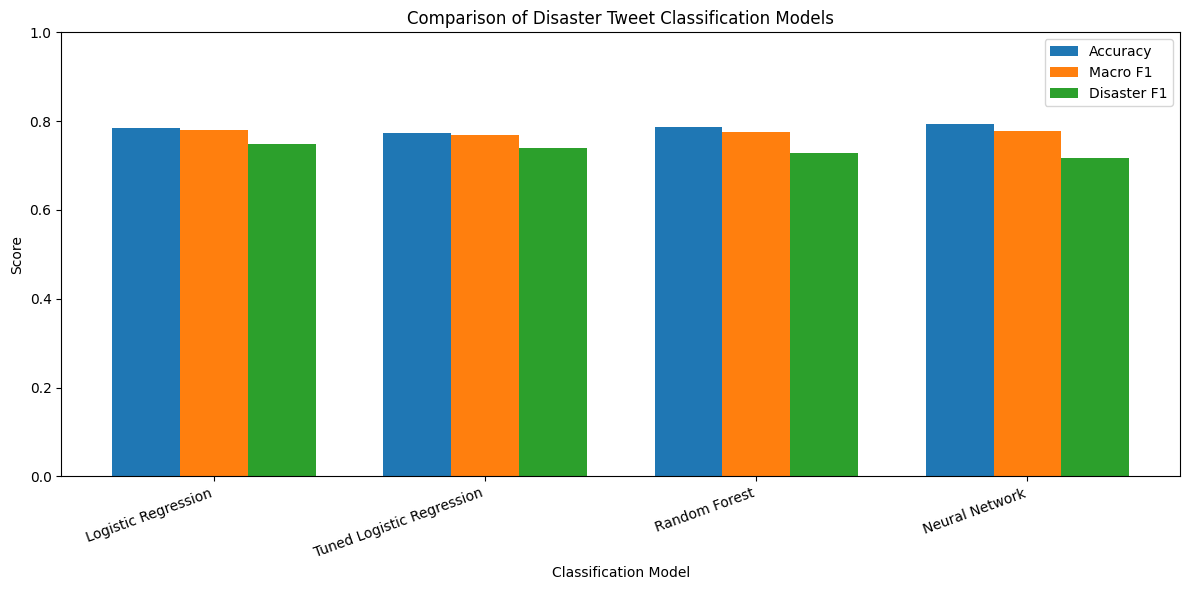

In [101]:
# Visualize model performance

# Prepare results
models = results["Model"]
accuracy = results["Accuracy"]
macro_f1 = results["Macro F1"]
disaster_f1 = results["Disaster F1"]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - width, accuracy, width, label="Accuracy")
plt.bar(x, macro_f1, width, label="Macro F1")
plt.bar(x + width, disaster_f1, width, label="Disaster F1")

plt.xticks(x, models, rotation=20, ha="right")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.title("Comparison of Disaster Tweet Classification Models")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


In [106]:
# Analyze the best model's errors


error_analysis = pd.DataFrame({
    "Tweet": X_test.reset_index(drop=True),
    "Actual": np.asarray(y_test),
    "Predicted": np.asarray(y_pred_lr)
})

# Keep only incorrect predictions
errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print("Total incorrect predictions:", len(errors))
print("\nFirst 10 misclassified tweets:")
print(errors.head(10).to_string(index=False))

Total incorrect predictions: 326

First 10 misclassified tweets:
                                                                                                                         Tweet  Actual  Predicted
      the quote website disaster tried 3 browsers amp 3 machines always get missing info error due to a non existant drop down       0          1
                                                             i may have gotten a little too exited over my home made lava lamp       0          1
                                     ok ok what if i make the close quarters an abandoned cabin in the woods in a thunderstorm       1          0
                                                                                                         sevenfigz has a crush       1          0
                                       infantry mens lume dial army analog quartz wrist watch sport blue nylon fabric full rea       0          1
                                 roof collapsed a bowling a

In [107]:
# Calculate false positives and false negatives

# False positives: actual 0, predicted 1
false_positives = errors[
    (errors["Actual"] == 0) &
    (errors["Predicted"] == 1)
]

# False negatives: actual 1, predicted 0
false_negatives = errors[
    (errors["Actual"] == 1) &
    (errors["Predicted"] == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

print("\nFalse positives as a percentage of all errors:",
      round(len(false_positives) / len(errors) * 100, 2), "%")

print("False negatives as a percentage of all errors:",
      round(len(false_negatives) / len(errors) * 100, 2), "%")

False positives: 164
False negatives: 162

False positives as a percentage of all errors: 50.31 %
False negatives as a percentage of all errors: 49.69 %


### Error Analysis and Model Limitations

The Logistic Regression classifier correctly classified 1,187 out of 1,513 test tweets and misclassified 326 tweets. The errors consisted of 164 false positives and 162 false negatives.

False positives included non-disaster tweets containing words associated with hazardous events, such as references to lava lamps. False negatives included tweets describing incidents such as a roof collapse. These examples suggest that keyword associations alone may not always distinguish actual disaster events from figurative language, hypothetical scenarios, or unrelated contexts.

To improve performance, future experiments could compare word-level and character-level TF-IDF features, incorporate additional features such as tweet length and hashtags, and evaluate alternative classification models. Model selection should consider both overall accuracy and class-specific precision, recall, and F1-score, particularly because missing genuine disaster reports may be costly.

# Part 3: Model Evaluation and Validation

In [110]:
# Generate the evaluation metrics table
from sklearn.metrics import precision_score, recall_score

models_predictions = {
    "Logistic Regression": y_pred_lr,
    "Tuned Logistic Regression": y_pred_tuned,
    "Random Forest": y_pred_rf,
    "Neural Network": y_pred_nn
}

evaluation_results = []

for model_name, predictions in models_predictions.items():
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df.round(4).to_string(index=False))

                    Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)
      Logistic Regression    0.7845             0.7800          0.7802            0.7801
Tuned Logistic Regression    0.7740             0.7692          0.7708            0.7699
            Random Forest    0.7865             0.7893          0.7719            0.7764
           Neural Network    0.7938             0.8150          0.7709            0.7775


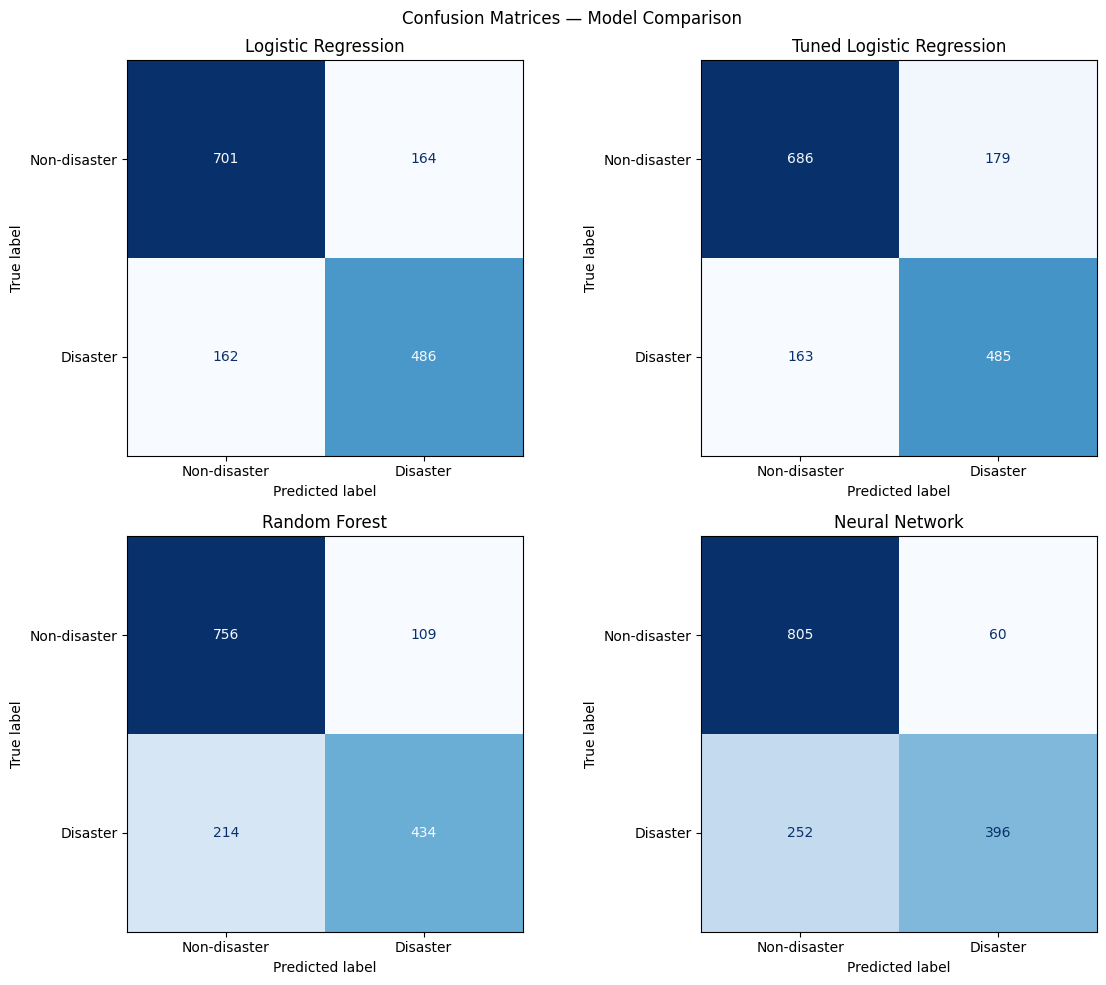

In [111]:
# Visualize confusion matrices

from sklearn.metrics import ConfusionMatrixDisplay

trained_models = {
    "Logistic Regression": lr_model,
    "Tuned Logistic Regression": best_lr_model,
    "Random Forest": rf_model,
    "Neural Network": nn_model
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions) in zip(
    axes.ravel(), models_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Non-disaster", "Disaster"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.suptitle("Confusion Matrices — Model Comparison")
plt.tight_layout()
plt.show()


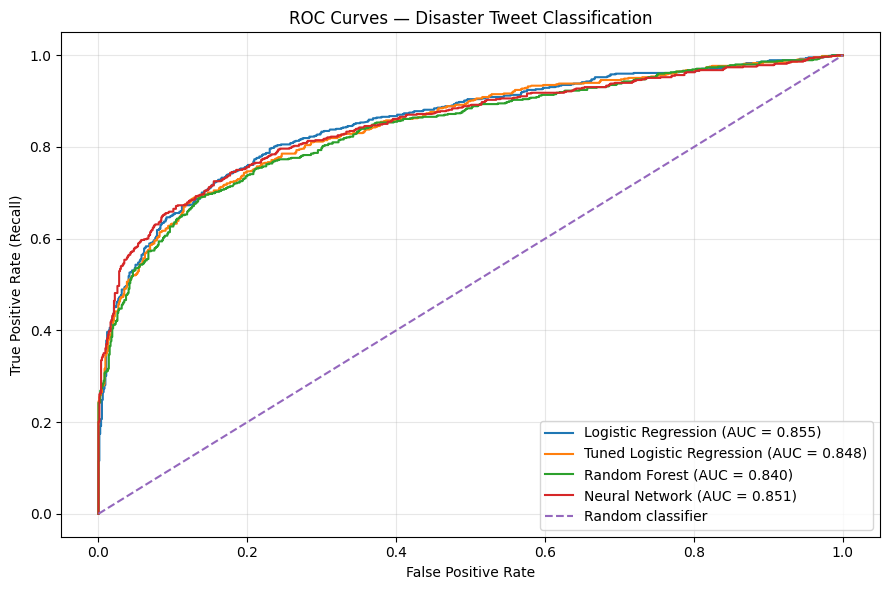

In [112]:
# Plot ROC curves

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, model in trained_models.items():
    # Probability of class 1 (disaster)
    y_score = model.predict_proba(X_test_combined)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc_score = roc_auc_score(y_test, y_score)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Disaster Tweet Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


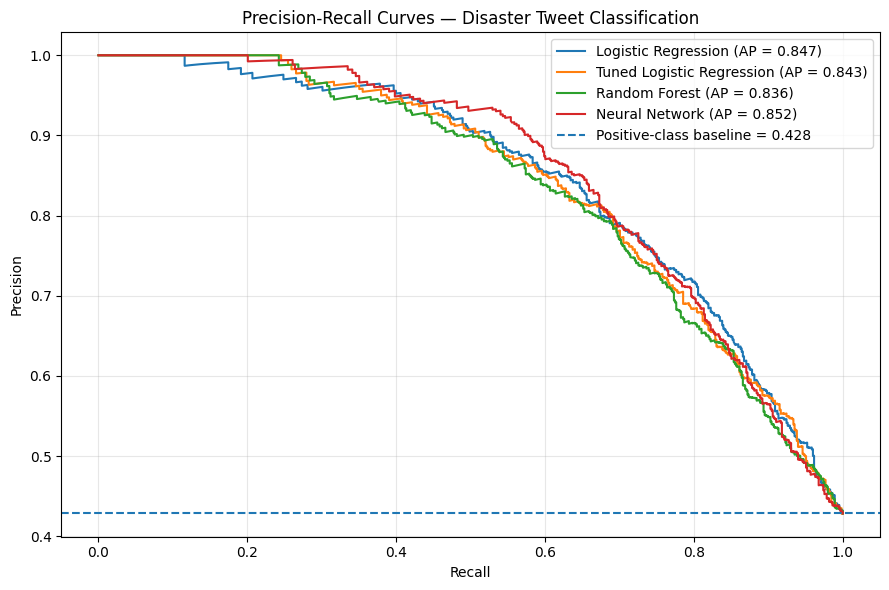

In [113]:
# Plot precision-recall curves

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(9, 6))

for name, model in trained_models.items():
    y_score = model.predict_proba(X_test_combined)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test, y_score
    )

    ap_score = average_precision_score(y_test, y_score)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap_score:.3f})"
    )

# Baseline precision equals the proportion of positive examples
baseline = (y_test == 1).mean()
plt.axhline(
    baseline,
    linestyle="--",
    label=f"Positive-class baseline = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Disaster Tweet Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [114]:
# Check for overfitting and underfitting

validation_results = []

for name, model in trained_models.items():
    # Predictions on training and test data
    train_predictions = model.predict(X_train_combined)
    test_predictions = model.predict(X_test_combined)

    train_accuracy = accuracy_score(
        y_train, train_predictions
    )
    test_accuracy = accuracy_score(
        y_test, test_predictions
    )

    train_f1 = f1_score(
        y_train, train_predictions, average="macro"
    )
    test_f1 = f1_score(
        y_test, test_predictions, average="macro"
    )

    validation_results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy,
        "Train Macro F1": train_f1,
        "Test Macro F1": test_f1,
        "Macro F1 Gap": train_f1 - test_f1
    })

validation_df = pd.DataFrame(validation_results)

print(validation_df.round(4).to_string(index=False))

                    Model  Train Accuracy  Test Accuracy  Accuracy Gap  Train Macro F1  Test Macro F1  Macro F1 Gap
      Logistic Regression          0.8758         0.7845        0.0913          0.8727         0.7801        0.0926
Tuned Logistic Regression          0.9688         0.7740        0.1948          0.9681         0.7699        0.1982
            Random Forest          0.8386         0.7865        0.0521          0.8306         0.7764        0.0542
           Neural Network          0.8778         0.7938        0.0840          0.8700         0.7775        0.0925


In [115]:
# Reduce overfitting in the tuned Logistic Regression model


from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

lr_regularized = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver="liblinear"
)

param_grid = {
    "C": [0.001, 0.01, 0.1, 1],
    "class_weight": [None, "balanced"]
}

regularization_search = GridSearchCV(
    estimator=lr_regularized,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

regularization_search.fit(X_train_combined, y_train)

print("Best parameters:", regularization_search.best_params_)
print("Best cross-validation Macro F1:",
      regularization_search.best_score_)

regularized_model = regularization_search.best_estimator_

y_pred_regularized = regularized_model.predict(X_test_combined)

print("\nTest accuracy:",
      accuracy_score(y_test, y_pred_regularized))

print("\nClassification report:")
print(classification_report(y_test, y_pred_regularized))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'C': 1, 'class_weight': None}
Best cross-validation Macro F1: 0.7812154670363334

Test accuracy: 0.7898215465961665

Classification report:
              precision    recall  f1-score   support

           0       0.79      0.86      0.82       865
           1       0.79      0.69      0.74       648

    accuracy                           0.79      1513
   macro avg       0.79      0.78      0.78      1513
weighted avg       0.79      0.79      0.79      1513



### Model Evaluation and Validation

Four classification models were evaluated: Logistic Regression, tuned Logistic Regression, Random Forest, and Neural Network. Evaluation metrics included accuracy, precision, recall, Macro F1-score, and class-specific F1-scores. Confusion matrices and misclassification analysis were used to examine false positives and false negatives.

The Neural Network achieved the highest test accuracy of 79.38%. However, the original Logistic Regression model achieved the highest Macro F1-score of 0.7801 and Disaster F1-score of 0.7488, making it a strong candidate when balanced classification performance and disaster detection are important.

Training-test comparisons indicated possible overfitting in several models. Tuned Logistic Regression showed the largest accuracy gap of 19.48 percentage points, while Random Forest had the smallest gap of 5.21 percentage points. The results demonstrate that the model with the highest training score is not necessarily the model that generalizes best to unseen tweets.

The original Logistic Regression model is the preferred candidate for further validation. Final selection should also consider ROC-AUC, precision-recall performance, and the relative cost of missed disaster reports versus false alarms. Further cross-validation and regularization experiments can help assess robustness before deployment.

###Part 4 — Deployment with Web Interface

In [116]:
# Save trained model and TF-IDF vectorizer


import os
import joblib

# Create a deployment folder in Google Drive
deployment_dir = (
    "/content/drive/MyDrive/Colab Notebooks/project7/deployment"
)

os.makedirs(deployment_dir, exist_ok=True)

print("Deployment folder created:", deployment_dir)


Deployment folder created: /content/drive/MyDrive/Colab Notebooks/project7/deployment


In [117]:
# Save both trained objects


# Save the trained TF-IDF vectorizer
joblib.dump(
    tfidf,
    os.path.join(deployment_dir, "tfidf_vectorizer.pkl")
)

# Save your preferred Logistic Regression model
joblib.dump(
    lr_model,
    os.path.join(deployment_dir, "disaster_model.pkl")
)

print("TF-IDF vectorizer and model saved successfully!")


TF-IDF vectorizer and model saved successfully!


In [118]:
# Verify that both files exist


print(os.listdir(deployment_dir))

# Verify that both files can be loaded
loaded_tfidf = joblib.load(
    os.path.join(deployment_dir, "tfidf_vectorizer.pkl")
)

loaded_model = joblib.load(
    os.path.join(deployment_dir, "disaster_model.pkl")
)

print("TF-IDF features:", len(loaded_tfidf.get_feature_names_out()))
print("Model classes:", loaded_model.classes_)


['tfidf_vectorizer.pkl', 'disaster_model.pkl']
TF-IDF features: 10000
Model classes: [0 1]


In [119]:
# Download the files for your Flask application


from google.colab import files

files.download(
    os.path.join(deployment_dir, "tfidf_vectorizer.pkl")
)

files.download(
    os.path.join(deployment_dir, "disaster_model.pkl")
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Additional Validation and Batch Inference

### Dataset size check
The supplied `twitter_disaster.csv` contains 7,613 rows (4,342 non-disaster and 3,271 disaster tweets). The project brief mentions 10,000 tweets, so the available dataset does not meet that stated size. The analysis below uses the supplied data as-is; no synthetic rows are added.

### Cross-validation across candidate models
The tuned Logistic Regression search above reports its 5-fold training cross-validation score. The following cell adds stratified 5-fold cross-validation for the baseline Logistic Regression, Random Forest, and Neural Network candidates. The held-out test set remains reserved for final evaluation.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "Neural Network": nn_model
}

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for model_name, estimator in cv_models.items():
    scores = cross_validate(
        clone(estimator),
        X_train_combined,
        y_train,
        cv=cv_splitter,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=True
    )
    cv_rows.append({
        "Model": model_name,
        "CV Accuracy (mean)": scores["test_accuracy"].mean(),
        "CV Precision Macro (mean)": scores["test_precision_macro"].mean(),
        "CV Recall Macro (mean)": scores["test_recall_macro"].mean(),
        "CV F1 Macro (mean)": scores["test_f1_macro"].mean(),
        "CV F1 Macro (std)": scores["test_f1_macro"].std(),
        "Train F1 Macro (mean)": scores["train_f1_macro"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    "CV F1 Macro (mean)", ascending=False
)
display(cv_results.round(4))

### Chunked batch prediction
The web page handles one tweet per request. This helper demonstrates offline/batch scoring in bounded chunks to avoid building one large feature matrix at once. It uses the same cleaning, TF-IDF, numeric feature order, sentiment analyzer, and Logistic Regression model as the web application. This supports batch processing but does not connect to or monitor a live social-media stream.

In [ ]:
from scipy.sparse import hstack, csr_matrix

def predict_tweets_in_batches(tweets, batch_size=1000):
    """Classify an iterable of tweets a chunk at a time."""
    if batch_size < 1:
        raise ValueError("batch_size must be at least 1")

    records = []
    tweets = list(tweets)
    for start in range(0, len(tweets), batch_size):
        batch = [
            "" if pd.isna(tweet) else str(tweet)
            for tweet in tweets[start:start + batch_size]
        ]
        cleaned = [clean_text(tweet) for tweet in batch]
        text_features = tfidf.transform(cleaned)
        extra_features = pd.DataFrame([{
            "tweet_length": len(tweet),
            "word_count": len(tweet.split()),
            "hashtag_count": len(re.findall(r"#\w+", tweet)),
            "mention_count": len(re.findall(r"@\w+", tweet)),
            "sentiment_compound": analyzer.polarity_scores(tweet)["compound"]
        } for tweet in batch])[extra_columns]
        combined = hstack([text_features, csr_matrix(extra_features.values)]).tocsr()
        predictions = lr_model.predict(combined)
        probabilities = (
            lr_model.predict_proba(combined)[:, 1]
            if hasattr(lr_model, "predict_proba") else [None] * len(batch)
        )
        records.extend({
            "tweet": tweet,
            "prediction": "Disaster" if label == 1 else "Non-Disaster",
            "disaster_probability": probability
        } for tweet, label, probability in zip(batch, predictions, probabilities))

    return pd.DataFrame(records)

# Example: process a small batch; replace this list with a larger collection.
sample_tweets = [
    "Flood water has entered several homes.",
    "That concert was fire!",
    "Roads are closed after the earthquake."
]
predict_tweets_in_batches(sample_tweets, batch_size=2)